# 06 – Le modèle de machine learning

**Objectif :** entraîner un vrai modèle qui combine *où* (commune), *quand* (saison) et *quelle météo*, et **battre la baseline** :
- PR-AUC > **0,048** sur la validation 2021-2022 ;
- plus de **32 %** des feux couverts en surveillant 5 % des couples commune × jour.

## Leçon 1 – Du arbre de décision au gradient boosting

### L'arbre de décision
Un **arbre de décision** est une suite de questions oui/non, comme un jeu de « Qui est-ce ? » :

```
                 bilan_hydrique_30j < -80 ?
                 /                      \
               oui                      non
               /                          \
   feux_commune_365j > 3 ?          risque 0,1 %
        /          \
      oui          non
      /              \
 risque 3 %      risque 0,8 %
```

L'algorithme choisit **lui-même** les questions et les seuils (−80, 3…) qui séparent le mieux les jours avec feu des jours sans feu, en essayant toutes les possibilités sur le jeu d'entraînement. Au bout de chaque branche (une **feuille**), il note le taux de feu observé : c'est la prédiction.

Un arbre seul est simple mais **grossier** : il ne peut poser que quelques questions.

### Le gradient boosting : une équipe d'arbres qui se corrigent
Le **gradient boosting** construit des centaines de petits arbres **les uns après les autres** :
1. le 1ᵉʳ arbre fait une prédiction grossière ;
2. le 2ᵉ arbre se concentre sur **les erreurs** du 1ᵉʳ et les corrige un peu ;
3. le 3ᵉ corrige les erreurs restantes… et ainsi de suite.

La prédiction finale est la **somme** des petites corrections de tous les arbres. C'est aujourd'hui la méthode la plus performante sur les données en tableau (comme les nôtres). LightGBM et XGBoost, dont tu entendras souvent parler, sont des variantes ; `HistGradientBoostingClassifier` est la version de scikit-learn, très proche de LightGBM.

> Pourquoi c'est adapté ici ? Au notebook 05, on a vu que le risque **n'augmente pas toujours** avec les jours sans pluie, et que la météo n'a pas le même effet partout. Les arbres capturent naturellement ce genre de relations « en escalier » et les **combinaisons** (« sec **ET** été **ET** commune à historique »).

## Leçon 2 – La « grammaire » de scikit-learn

Tous les modèles scikit-learn s'utilisent de la même façon, en 3 temps :

```python
modele = UnModele(reglages...)           # 1. créer le modèle (vide)
modele.fit(X_train, y_train)             # 2. l'entraîner (il apprend)
proba = modele.predict_proba(X_valid)    # 3. prédire sur de nouvelles données
```

- **`X`** = le tableau des features (les colonnes explicatives) – une majuscule par convention, car c'est une matrice ;
- **`y`** = la cible (`feu`) – une minuscule, car c'est un vecteur (une seule colonne).

Une fois cette grammaire apprise, tu sais utiliser des dizaines de modèles différents.

## Étape 1 – Charger les données et ajouter la position des communes

On ajoute la **latitude** et la **longitude** de chaque commune. Pourquoi pas directement le `code` INSEE ?
Parce que le modèle traiterait `13055` comme un **nombre** : il pourrait conclure que « 13055 > 13001 » veut dire quelque chose, ce qui est absurde. Les coordonnées, elles, ont un **sens géographique** : le modèle peut apprendre des zones (« au sud-est de tel point, risque plus élevé » → les massifs autour de Marseille).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.inspection import permutation_importance

df = pd.read_csv("../data/processed/features_13.csv", dtype={"code": str}, parse_dates=["jour"])
communes = pd.read_csv("../data/processed/communes_13.csv", dtype={"code": str})
df = df.merge(communes[["code", "lat", "lon"]], on="code", how="left")
df["annee"] = df["jour"].dt.year
print(df.shape)

(434707, 25)


## Étape 2 – Préparer X et y

On liste explicitement les features données au modèle. On **exclut** :
- `feu` : c'est la cible (la donner au modèle serait lui donner la réponse !) ;
- `jour`, `annee` : on ne veut pas que le modèle apprenne « en 2022 il y a eu beaucoup de feux » – c'est inutilisable pour prédire 2026 ;
- `code` : remplacé par `lat` / `lon`.

Puis on reprend **exactement le même découpage temporel** qu'au notebook 05 – indispensable pour comparer avec la baseline.

In [2]:
FEATURES = [
    # calendrier
    "mois", "jour_annee", "jour_semaine", "week_end",
    # météo du jour
    "temp_max", "humidite_min", "vent_max", "pluie", "evapo",
    # météo des jours passés
    "pluie_7j", "pluie_30j", "evapo_30j", "temp_max_7j", "bilan_hydrique_30j",
    "jours_sans_pluie", "vent_fort",
    # historique de feux (décalé d'un jour)
    "feux_commune_365j", "feux_commune_cumul", "feux_dept_veille",
    # géographie
    "lat", "lon",
]

train = df[df["annee"] <= 2020]
valid = df[df["annee"].between(2021, 2022)]
test  = df[df["annee"] >= 2023]   # toujours sous clé

X_train, y_train = train[FEATURES], train["feu"]
X_valid, y_valid = valid[FEATURES], valid["feu"]

print(X_train.shape, X_valid.shape)

(217413, 21) (86870, 21)


On réutilise la fonction de couverture du notebook 05, et on recalcule le score de la baseline pour l'avoir sous la main :

In [3]:
def part_feux_couverte(y, score, part=0.05):
    d = pd.DataFrame({"feu": np.asarray(y), "score": np.asarray(score)})
    n = int(len(d) * part)
    return d.sort_values("score", ascending=False).head(n)["feu"].sum() / d["feu"].sum()

taux_commune_mois = train.groupby(["code", "mois"])["feu"].mean().rename("score_baseline")
score_baseline = valid.merge(taux_commune_mois, left_on=["code", "mois"], right_index=True, how="left")["score_baseline"]

print("Baseline  PR-AUC =", round(average_precision_score(y_valid, score_baseline), 4),
      "| top 5 % →", f"{part_feux_couverte(y_valid, score_baseline):.0%} des feux")

Baseline  PR-AUC = 0.0484 | top 5 % → 32% des feux


## Étape 3 – Premier essai : le modèle avec ses réglages par défaut

`random_state=42` fixe le « hasard » interne du modèle : on obtiendra exactement le même résultat à chaque exécution (reproductibilité). 42 est une blague de geek, n'importe quel nombre marche.

`predict_proba` renvoie **deux colonnes** : la probabilité de « pas de feu » (colonne 0) et celle de « feu » (colonne 1). `[:, 1]` signifie « toutes les lignes, colonne 1 ».

In [4]:
modele_defaut = HistGradientBoostingClassifier(random_state=42)
modele_defaut.fit(X_train, y_train)

proba_valid = modele_defaut.predict_proba(X_valid)[:, 1]
proba_train = modele_defaut.predict_proba(X_train)[:, 1]

print("PR-AUC sur le TRAIN      :", round(average_precision_score(y_train, proba_train), 4))
print("PR-AUC sur la VALIDATION :", round(average_precision_score(y_valid, proba_valid), 4))
print("Couverture top 5 %       :", f"{part_feux_couverte(y_valid, proba_valid):.0%}")

PR-AUC sur le TRAIN      : 0.2285
PR-AUC sur la VALIDATION : 0.0343
Couverture top 5 %       : 27%


😬 **Le modèle par défaut fait moins bien que la baseline !** Et regarde l'écart entre le score sur le train et sur la validation.

## Leçon 3 – Le surapprentissage (*overfitting*)

Le modèle est **bien meilleur sur les données qu'il a vues** (train) que sur des données nouvelles (validation). C'est le signe du **surapprentissage** : au lieu d'apprendre des règles générales (« sécheresse + vent = danger »), il a en partie **appris par cœur** les particularités du train (« le 14 juillet 2017 à Istres, il y a eu un feu »).

C'est comme un élève qui apprend les corrigés des annales par cœur : excellent sur les annales, perdu le jour de l'examen.

Pourquoi c'est particulièrement dangereux ici ? Avec seulement **1 069 jours avec feu** dans le train, chaque feu « pèse » beaucoup : un arbre peut facilement créer une feuille qui isole 3 ou 4 feux par hasard, puis en faire une règle.

**Le remède : contraindre le modèle** pour qu'il ne puisse apprendre que des règles **solides**, appuyées sur beaucoup d'exemples. C'est le rôle des **hyperparamètres**.

## Étape 4 – Les hyperparamètres

Les **hyperparamètres** sont les réglages qu'on choisit **avant** l'entraînement (le modèle ne les apprend pas). Les plus importants ici :

| Hyperparamètre | Rôle | Défaut | Effet anti-surapprentissage |
|---|---|---|---|
| `max_leaf_nodes` | nombre max de feuilles par arbre | 31 | **moins** de feuilles = arbres plus simples |
| `min_samples_leaf` | nombre min de lignes dans une feuille | 20 | **plus** = chaque règle doit s'appuyer sur beaucoup de jours |
| `learning_rate` | taille de chaque correction | 0,1 | **plus petit** = corrections plus prudentes |
| `max_iter` | nombre d'arbres | 100 | à ajuster avec le `learning_rate` |
| `early_stopping` | arrêt automatique | auto | on le désactive : il utilise un tirage **au hasard** de lignes, contraire à notre logique temporelle |

**Règle d'or : on choisit les hyperparamètres sur la VALIDATION, jamais sur le test.**

On essaie plusieurs combinaisons avec deux boucles imbriquées (c'est ce qu'on appelle une **recherche sur grille**, *grid search*) : 9 modèles à entraîner, compte 1 à 2 minutes.

In [5]:
essais = []
for feuilles in [31, 15, 7]:
    for min_feuille in [20, 200, 1000]:
        m = HistGradientBoostingClassifier(
            learning_rate=0.03, max_iter=300, early_stopping=False,
            max_leaf_nodes=feuilles, min_samples_leaf=min_feuille,
            random_state=42,
        )
        m.fit(X_train, y_train)
        p = m.predict_proba(X_valid)[:, 1]
        essais.append({
            "max_leaf_nodes": feuilles,
            "min_samples_leaf": min_feuille,
            "PR-AUC": round(average_precision_score(y_valid, p), 4),
            "top 5 %": round(float(part_feux_couverte(y_valid, p)), 3),
        })
        print(essais[-1])

grille = pd.DataFrame(essais).sort_values("PR-AUC", ascending=False)
grille

{'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'PR-AUC': 0.0472, 'top 5 %': 0.366}


{'max_leaf_nodes': 31, 'min_samples_leaf': 200, 'PR-AUC': 0.0623, 'top 5 %': 0.363}


{'max_leaf_nodes': 31, 'min_samples_leaf': 1000, 'PR-AUC': 0.0652, 'top 5 %': 0.373}


{'max_leaf_nodes': 15, 'min_samples_leaf': 20, 'PR-AUC': 0.0534, 'top 5 %': 0.363}


{'max_leaf_nodes': 15, 'min_samples_leaf': 200, 'PR-AUC': 0.0625, 'top 5 %': 0.366}


{'max_leaf_nodes': 15, 'min_samples_leaf': 1000, 'PR-AUC': 0.0671, 'top 5 %': 0.37}


{'max_leaf_nodes': 7, 'min_samples_leaf': 20, 'PR-AUC': 0.0588, 'top 5 %': 0.372}


{'max_leaf_nodes': 7, 'min_samples_leaf': 200, 'PR-AUC': 0.0625, 'top 5 %': 0.381}


{'max_leaf_nodes': 7, 'min_samples_leaf': 1000, 'PR-AUC': 0.0699, 'top 5 %': 0.378}


,max_leaf_nodes,min_samples_leaf,PR-AUC,top 5 %
8,7,1000,0.0699,0.378
5,15,1000,0.0671,0.370
2,31,1000,0.0652,0.373
7,7,200,0.0625,0.381
4,15,200,0.0625,0.366
1,31,200,0.0623,0.363
6,7,20,0.0588,0.372
3,15,20,0.0534,0.363
0,31,20,0.0472,0.366


`essais[-1]` = le dernier élément de la liste (les indices négatifs comptent depuis la fin).

**Lecture :** plus on contraint le modèle (peu de feuilles, beaucoup de lignes minimum par feuille), meilleur il est sur la validation. Avec nos feux rares, **la simplicité gagne**. Le tableau croisé (pivot) ci-dessous le rend visible d'un coup d'œil :

In [6]:
grille.pivot(index="max_leaf_nodes", columns="min_samples_leaf", values="PR-AUC")

min_samples_leaf,20,200,1000
max_leaf_nodes,,,
7,0.0588,0.0625,0.0699
15,0.0534,0.0625,0.0671
31,0.0472,0.0623,0.0652


## Étape 5 – Le modèle retenu

On garde la meilleure combinaison : **7 feuilles, au moins 1 000 lignes par feuille**.

In [7]:
REGLAGES = dict(
    learning_rate=0.03, max_iter=300, early_stopping=False,
    max_leaf_nodes=7, min_samples_leaf=1000, random_state=42,
)

modele = HistGradientBoostingClassifier(**REGLAGES)
modele.fit(X_train, y_train)
proba_valid = modele.predict_proba(X_valid)[:, 1]

print("PR-AUC train      :", round(average_precision_score(y_train, modele.predict_proba(X_train)[:, 1]), 4))
print("PR-AUC validation :", round(average_precision_score(y_valid, proba_valid), 4))

PR-AUC train      : 0.1055
PR-AUC validation : 0.0699


`**REGLAGES` « déballe » le dictionnaire : c'est comme écrire `learning_rate=0.03, max_iter=300, ...` à la main. Pratique pour réutiliser les mêmes réglages plus loin.

L'écart train / validation s'est nettement réduit : le modèle apprend des règles plus **générales**.

### Le verdict sur la validation

In [8]:
comparaison = pd.DataFrame({
    "méthode": ["Baseline commune × mois", "Modèle par défaut", "Modèle réglé"],
    "PR-AUC": [average_precision_score(y_valid, s) for s in [score_baseline, modele_defaut.predict_proba(X_valid)[:, 1], proba_valid]],
    "top 5 %": [part_feux_couverte(y_valid, s) for s in [score_baseline, modele_defaut.predict_proba(X_valid)[:, 1], proba_valid]],
})
comparaison["× hasard"] = comparaison["PR-AUC"] / y_valid.mean()
comparaison.style.format({"PR-AUC": "{:.4f}", "top 5 %": "{:.0%}", "× hasard": "{:.1f}"})

,méthode,PR-AUC,top 5 %,× hasard
0,Baseline commune × mois,0.0484,32%,6.2
1,Modèle par défaut,0.0343,27%,4.4
2,Modèle réglé,0.0699,38%,8.9


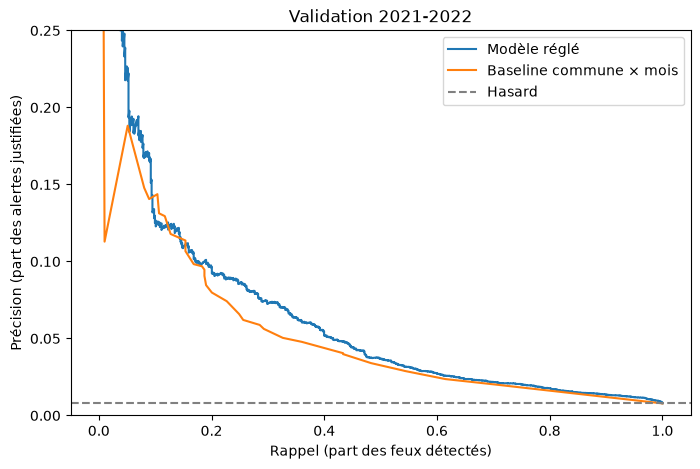

In [9]:
plt.figure(figsize=(8, 5))
for nom, score in [("Modèle réglé", proba_valid), ("Baseline commune × mois", score_baseline)]:
    precision, rappel, _ = precision_recall_curve(y_valid, score)
    plt.plot(rappel, precision, label=nom)
plt.axhline(y_valid.mean(), color="grey", linestyle="--", label="Hasard")
plt.xlabel("Rappel (part des feux détectés)")
plt.ylabel("Précision (part des alertes justifiées)")
plt.title("Validation 2021-2022")
plt.ylim(0, 0.25)
plt.legend()
plt.show()

🎉 **Le modèle réglé bat la baseline** sur les deux critères : PR-AUC environ **+45 %**, et plus de feux couverts au top 5 %. Sa courbe est au-dessus de celle de la baseline presque partout.

## Étape 6 – Qu'est-ce que le modèle a appris ?

Un modèle qui marche, c'est bien ; un modèle qu'on **comprend**, c'est mieux (et indispensable pour convaincre un utilisateur).

### Leçon 4 – L'importance par permutation
Idée simple : pour mesurer l'importance d'une feature, on **mélange** ses valeurs au hasard dans la validation (on casse son lien avec la cible) et on regarde **combien la PR-AUC baisse**.
- grosse baisse → le modèle comptait beaucoup sur cette feature ;
- aucune baisse → il ne s'en sert pas (ou une autre feature lui donne la même info).

`n_repeats=3` : on mélange 3 fois et on fait la moyenne, pour lisser le hasard. Compte environ 1 minute.

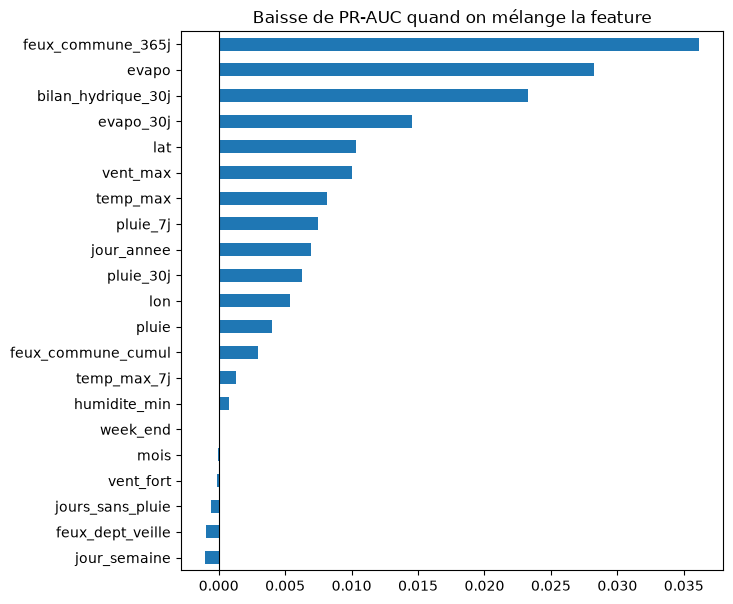

In [10]:
imp = permutation_importance(
    modele, X_valid, y_valid,
    scoring="average_precision", n_repeats=3, random_state=42,
)
importances = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

importances.plot(kind="barh", figsize=(7, 7), title="Baisse de PR-AUC quand on mélange la feature")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

**Ce qu'on lit (vérifie sur ton graphique) :**
- **`feux_commune_365j`** arrive en tête : l'historique récent de la commune reste le meilleur prédicteur (le « où »).
- Juste derrière, la **météo de sécheresse** : `evapo`, `bilan_hydrique_30j`, `evapo_30j` – exactement l'indicateur « métier » qu'on avait construit au notebook 04.
- Puis le **vent** et la **position** (`lat`, `lon`).

**Piège d'interprétation :** `jours_sans_pluie` ou `feux_dept_veille` semblent inutiles. Ça ne veut pas dire qu'ils n'ont pas de lien avec les feux (on a vu le contraire au notebook 04 !), mais que **d'autres features portent déjà la même information** : quand on mélange `jours_sans_pluie`, le modèle se rabat sur `bilan_hydrique_30j`. On dit que ces features sont **corrélées**. L'importance par permutation mesure ce qu'une feature apporte **en plus des autres**.

## Étape 7 – Le moment de vérité : le jeu de test

Tous nos choix (features, hyperparamètres) sont faits. On ouvre enfin le **jeu de test (2023-2025)**, **une seule fois**. S'il est mauvais, on ne revient pas « bricoler » pour l'améliorer : ce serait tricher (il deviendrait une 2ᵉ validation).

On fait comme en conditions réelles : avant de prédire 2023-2025, on aurait utilisé **toutes** les données disponibles. On **réentraîne** donc le modèle (mêmes réglages) sur **train + validation (2016-2022)**, et on recalcule aussi la baseline sur 2016-2022 pour que la comparaison soit équitable.

In [11]:
train_complet = df[df["annee"] <= 2022]

modele_final = HistGradientBoostingClassifier(**REGLAGES)
modele_final.fit(train_complet[FEATURES], train_complet["feu"])
proba_test = modele_final.predict_proba(test[FEATURES])[:, 1]

taux_final = train_complet.groupby(["code", "mois"])["feu"].mean().rename("score_baseline")
baseline_test = test.merge(taux_final, left_on=["code", "mois"], right_index=True, how="left")["score_baseline"].values

y_test = test["feu"]
print(f"Taux de feu du test : {y_test.mean():.2%}\n")
print(f"{'':10} {'PR-AUC':>8} {'top 5 %':>8}")
print(f"{'Baseline':10} {average_precision_score(y_test, baseline_test):>8.4f} {part_feux_couverte(y_test, baseline_test):>8.0%}")
print(f"{'Modèle':10} {average_precision_score(y_test, proba_test):>8.4f} {part_feux_couverte(y_test, proba_test):>8.0%}")

Taux de feu du test : 0.56%

             PR-AUC  top 5 %
Baseline     0.0401      38%
Modèle       0.0630      42%


Le modèle bat la baseline **aussi sur le test** : le gain trouvé en validation n'était pas un coup de chance. C'est **ce** résultat qu'on mettra dans le README.

Vérifions année par année : un bon modèle doit être meilleur **chaque** année, pas seulement en moyenne.

In [12]:
par_annee = []
for annee in [2023, 2024, 2025]:
    masque = (test["annee"] == annee).values
    par_annee.append({
        "année": annee,
        "taux de feu": y_test[masque].mean(),
        "PR-AUC baseline": average_precision_score(y_test[masque], baseline_test[masque]),
        "PR-AUC modèle": average_precision_score(y_test[masque], proba_test[masque]),
    })
pd.DataFrame(par_annee).style.format({"taux de feu": "{:.2%}", "PR-AUC baseline": "{:.4f}", "PR-AUC modèle": "{:.4f}"})

,année,taux de feu,PR-AUC baseline,PR-AUC modèle
0,2023,0.62%,0.0344,0.0621
1,2024,0.48%,0.0387,0.0458
2,2025,0.58%,0.0515,0.0837


`masque` est un tableau de Vrai/Faux : `y_test[masque]` ne garde que les lignes où il vaut Vrai (ici, l'année voulue). C'est la façon standard de **filtrer** en numpy/pandas.

## Étape 8 – Sauvegarder les prédictions

On sauvegarde les probabilités du test : elles serviront à la **carte interactive du risque** (prochaine étape).

In [13]:
predictions = test[["code", "jour", "feu"]].copy()
predictions["proba_modele"] = proba_test
predictions["score_baseline"] = baseline_test
predictions.to_csv("../data/processed/predictions_test.csv", index=False)
predictions.sort_values("proba_modele", ascending=False).head(10)

,code,jour,feu,proba_modele,score_baseline
204411,13056,2025-07-28,1,0.448713,0.211982
203690,13056,2023-08-07,0,0.448299,0.147465
203688,13056,2023-08-05,1,0.396069,0.147465
203687,13056,2023-08-04,0,0.393809,0.147465
200036,13055,2023-08-06,0,0.387566,0.036866
200024,13055,2023-07-25,1,0.383305,0.101382
200368,13055,2024-07-03,0,0.377630,0.101382
200037,13055,2023-08-07,0,0.364802,0.036866
203689,13056,2023-08-06,1,0.355870,0.147465
200367,13055,2024-07-02,0,0.355663,0.101382


Les 10 couples commune × jour les plus risqués selon le modèle : regarde les dates (été ?) et la colonne `feu` (combien ont réellement brûlé ?).

**À toi de jouer :** à l'aide de `communes`, ajoute le nom des communes à ce top 10 (indice : un `merge` sur `code`). Reconnais-tu les communes de l'exploration du notebook 01 ?

In [14]:
# Correction
top10 = predictions.sort_values("proba_modele", ascending=False).head(10)
top10 = top10.merge(communes[["code", "nom"]], on="code", how="left")
top10[["nom", "jour", "proba_modele", "feu"]]

,nom,jour,proba_modele,feu
0,Martigues,2025-07-28,0.448713,1
1,Martigues,2023-08-07,0.448299,0
2,Martigues,2023-08-05,0.396069,1
3,Martigues,2023-08-04,0.393809,0
4,Marseille,2023-08-06,0.387566,0
5,Marseille,2023-07-25,0.383305,1
6,Marseille,2024-07-03,0.377630,0
7,Marseille,2023-08-07,0.364802,0
8,Martigues,2023-08-06,0.355870,1
9,Marseille,2024-07-02,0.355663,0


### Correction de l'exercice, pas à pas

1. **`predictions.sort_values("proba_modele", ascending=False)`** : on trie toutes les lignes du test de la plus risquée à la moins risquée (`ascending=False` = ordre décroissant).
2. **`.head(10)`** : on garde les 10 premières.
3. **`.merge(communes[["code", "nom"]], on="code", how="left")`** : la RECHERCHEV. Pour chaque ligne du top 10, pandas va chercher dans `communes` la ligne qui a le même `code` et rapporte la colonne `nom`.
   - `communes[["code", "nom"]]` : on ne prend que les 2 colonnes utiles (sinon `lat`, `lon` viendraient aussi). Note les **doubles crochets** : `[["a", "b"]]` = une liste de colonnes → un tableau ; `["a"]` = une seule colonne.
   - `how="left"` : on garde toutes les lignes du top 10, même si un code n'était pas trouvé.
4. **`top10[["nom", "jour", "proba_modele", "feu"]]`** : on choisit les colonnes à afficher, dans l'ordre voulu.

**Ce qu'on voit :** le top 10 est occupé par **Martigues** et **Marseille** en plein été (juillet-août 2023, 2024, 2025) – les deux communes en tête du nombre de feux au notebook 01. Et environ 4 de ces 10 couples ont réellement brûlé (`feu = 1`), alors que le taux moyen est de 0,56 % : le modèle concentre bien le risque.

**Bonus :** remplace `head(10)` par `head(50)` et compte les feux avec `top10["feu"].sum()`.

## Récap du notebook

1. **Gradient boosting** = des centaines de petits arbres de décision, chacun corrigeant les erreurs des précédents.
2. **Grammaire scikit-learn** : `fit(X, y)` pour apprendre, `predict_proba(X)` pour prédire.
3. **Surapprentissage** : le modèle par défaut apprenait par cœur (excellent en train, moins bon que la baseline en validation). On l'a contraint avec les **hyperparamètres** (peu de feuilles, beaucoup de lignes par feuille), choisis **sur la validation**.
4. **Importance par permutation** : historique de la commune, puis sécheresse (évapotranspiration, bilan hydrique), vent et position. Attention aux features corrélées.
5. **Test ouvert une seule fois**, après réentraînement sur 2016-2022 : le modèle bat la baseline, globalement et chaque année.

**Prochaine étape (07) :** la **carte interactive du risque** avec folium, puis le README GitHub.